In [1]:
from geodesic_toolbox import (
    CoMetric,
    RandersMetrics,
)
from finsler_learning.shepplogan_pipeline.shepplogan_utils import *
from finsler_learning.base_classic_regressor import HybridRegressor
from finsler_learning.shepplogan_pipeline.shepplogan_image_regressor import (
    get_image_regressor,
    get_vae_shepplogan_dataloaders,
)
from finsler_learning.shepplogan_pipeline.shepplogan_randers_training import get_omega
from finsler_learning.base_geodesic_evaluation import (
    GeodesicSolverParams,
    GeodesicEvalFinslerConfig,
    GeodesicEvalRiemannConfig,
    geodesic_evaluation,
)
from finsler_learning.base_quality_evaluation import evaluate_framework
import json
import torch
from einops import rearrange
import matplotlib.pyplot as plt
import numpy as np
from finsler_learning.base_geodesic_evaluation import (
    get_ordered_data_fixed,
    retrieve_time_from_traj,
)
from finsler_learning.base_geodesic_evaluation import kendall_tau as get_kendall_tau
from finsler_learning.base_geodesic_evaluation import get_solver
from finsler_learning.shepplogan_pipeline.shepplogan_utils import (
    get_cometric,
    VALID_COMETRIC_TYPES,
)
from finsler_learning.shepplogan_pipeline.shepplogan_interpolation import (
    get_randers_metric_trained,
)
from finsler_learning.shepplogan_pipeline.shepplogan_interpolation import (
    get_model_regressor_trained,
)
import ot
import pandas as pd
import seaborn as sns

/home/tblanchard/phd/finsler_learning/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
base_path = Path("/home/tblanchard/phd/finsler_learning/results/shepplogan/runs_2026-11-11")
with open(base_path / "shepplogan_pipeline_config.json", "r") as f:
    config = json.load(f)
config = SheppLoganPipelineConfig(**config)
config.export_path = Path(config.export_path)

In [3]:
methods = [
    ("Euclidean", "euclidean"),
    ("LAND", "land"),
    ("LAND RBF", "land_rbf"),
    ("CovCentroids", "cov_centroids"),
    ("PBCentroids", "pullback_centroids"),
    # ("RBF PB", "rbf_pullback"),
    # ("PBIG", "pbig"),
    # ("WarpedPB", "warped_pullback"),
    # ("Wasserstein", "wasserstein"),
    # ("HyperSpherical", "spherical"),
]

In [4]:
model = get_models(latent_dim=config.latent_dim)
dtype = next(model.parameters()).dtype
try_load_pretrained_models(config.export_path, model)
model = model.to(config.device)
model.eval()

regressor = get_model_regressor_trained(
    export_path=config.export_path,
    device=config.device,
).to(dtype)

dl_config = DatasetConfig(batch_size=config.b_size_evaluation)
shepp_logan_trainloader, shepp_logan_test_loader = get_shepplogan_dataloaders(
    dataset_config=dl_config,
    export_path=config.export_path,
)
LOGGER.info(f"Generating the images for the quality evaluation...")
shepp_logan_trainloader_vae, _ = get_vae_shepplogan_dataloaders(
    dataset_config=dl_config,
    latent_dim=config.latent_dim,
    device=config.device,
    export_path=config.export_path,
)
if config.K_cometric is None:
    k = len(shepp_logan_trainloader.dataset)

encoder = model.encoder.to(config.device)
decoder = model.decoder.to(config.device)
encoder.eval()
decoder.eval()
0

100%|██████████| 500/500 [00:07<00:00, 62.51it/s]


0

In [5]:
def embed_dataset_(dataloader, encoder, device):
    embeddings = []
    labels = []
    with torch.no_grad():
        for batch in tqdm(dataloader):
            images, batch_labels = batch
            images = images.to(device)
            embedding, _ = encoder(images)
            embeddings.append(embedding.cpu())
            labels.append(batch_labels)
    embeddings = torch.cat(embeddings, dim=0)
    labels = torch.cat(labels, dim=0)
    return embeddings, labels


z_train, _ = embed_dataset_(shepp_logan_trainloader, encoder, config.device)
z_test, _ = embed_dataset_(shepp_logan_test_loader, encoder, config.device)

100%|██████████| 16/16 [00:08<00:00,  1.86it/s]


In [6]:
VALID_COMETRIC_TYPES

{'euclidean': {'needs_spline': False, 'requires_stochastic_vae': False},
 'land_rbf': {'needs_spline': False, 'requires_stochastic_vae': False},
 'land': {'needs_spline': False, 'requires_stochastic_vae': False},
 'cov_centroids': {'needs_spline': False, 'requires_stochastic_vae': False},
 'pullback_centroids': {'needs_spline': True,
  'requires_stochastic_vae': False},
 'euclidean_biased': {'needs_spline': False,
  'requires_stochastic_vae': False,
  'is_riemann_biased': True},
 'land_rbf_biased': {'needs_spline': False,
  'requires_stochastic_vae': False,
  'is_riemann_biased': True},
 'land_biased': {'needs_spline': False,
  'requires_stochastic_vae': False,
  'is_riemann_biased': True},
 'cov_centroids_biased': {'needs_spline': False,
  'requires_stochastic_vae': False,
  'is_riemann_biased': True},
 'pullback_centroids_biased': {'needs_spline': True,
  'requires_stochastic_vae': False,
  'is_riemann_biased': True}}

In [7]:
@torch.no_grad()
def get_centroids_cometric_centroids(config: SheppLoganPipelineConfig):
    # Don't bother with all the params as it's going to load generated data anyway
    dl_config = DatasetConfig(
        batch_size=config.b_size_evaluation,
    )
    shepplogan_train_loader, _ = get_shepplogan_dataloaders(
        dataset_config=dl_config, export_path=config.export_path
    )
    model = get_models(latent_dim=config.latent_dim)
    try_load_pretrained_models(config.export_path, model)
    model.eval()
    centroids, _, _ = embed_dataset(model.encoder, shepplogan_train_loader, config.device)
    pullback_cometric = PullBackCometric(
        diffeo=model.decoder,
        reg_coef=0.0,  # We want exact pullback cometric, no regularization
        method="finite_difference",  # We want exact pullback cometric, no finite difference
        chunk_size=8,
    ).to(config.device)
    centroids_cometric = []
    pbar = tqdm(
        range(0, len(centroids), 16),
        desc="Computing pullback cometric",
        leave=False,
        total=len(centroids),
    )
    for b_idx in pbar:
        z = centroids[b_idx : b_idx + 16].to(config.device)
        G_inv = pullback_cometric.cometric_tensor(z)
        centroids_cometric.append(G_inv)
        pbar.update(min(16, len(centroids) - b_idx) - 1)
    pbar.close()

    centroids_cometric = torch.cat(centroids_cometric, dim=0)
    return centroids, centroids_cometric


# centroids, centroids_cometric = get_centroids_cometric_centroids(config)

In [8]:
all_densities = {}
for cometric_type, metric_info in VALID_COMETRIC_TYPES.items():
    if "biased" in cometric_type:
        continue
    print(f"Evaluating cometric: {cometric_type}")
    cometric = get_cometric(
        latent_dim=config.latent_dim,
        export_path=config.export_path,
        k=config.K_cometric,
        batch_size=config.b_size_evaluation,
        cometric_type=cometric_type,
        device=config.device,
    )  # .to(dtype)

    p_train = cometric.inv_logdet(z_train.to(config.device)).cpu().detach()
    p_test = cometric.inv_logdet(z_test.to(config.device)).cpu().detach()

    all_densities[cometric_type] = {
        "train": p_train,
        "test": p_test,
    }

Evaluating cometric: euclidean
Evaluating cometric: land_rbf


Evaluating cometric: land
Evaluating cometric: cov_centroids
Evaluating cometric: pullback_centroids


In [9]:
w2_distances = {}
for cometric_type, densities_res in all_densities.items():
    p_train = densities_res["train"]
    p_test = densities_res["test"]
    # Compute the W2 distance between the train and test densities
    w2_distance = ot.wasserstein_1d(p_train.numpy(), p_test.numpy())
    w2_distances[cometric_type] = w2_distance

In [10]:
df_densities = pd.DataFrame.from_dict(all_densities, orient="index", columns=["train", "test"])
df_w2_distances = pd.DataFrame.from_dict(w2_distances, orient="index", columns=["W2_distance"])

/tmp/ipykernel_2533363/1563262086.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


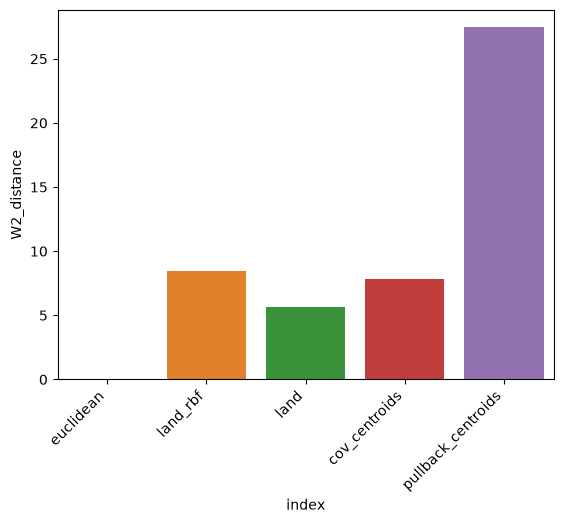

In [11]:
sns.barplot(data=df_w2_distances.reset_index(), x="index", y="W2_distance", hue="index")
ax = plt.gca()
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

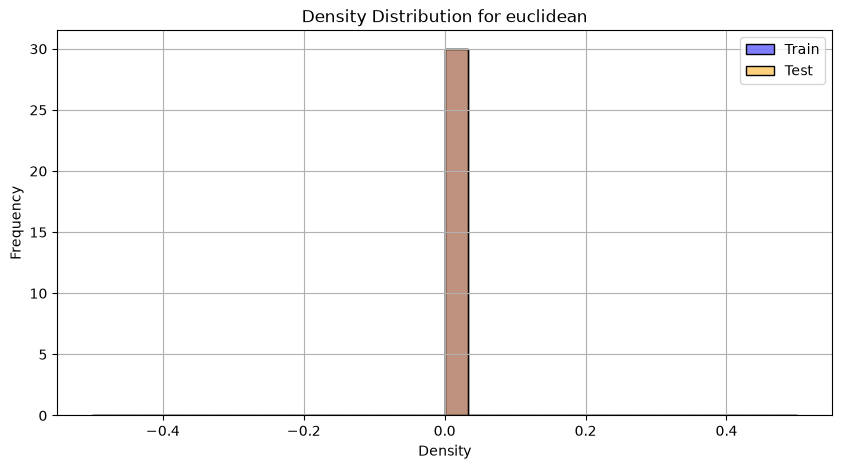

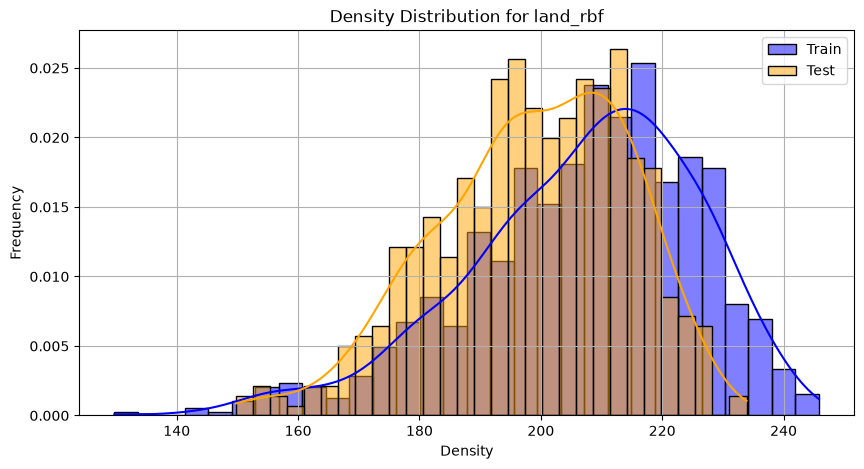

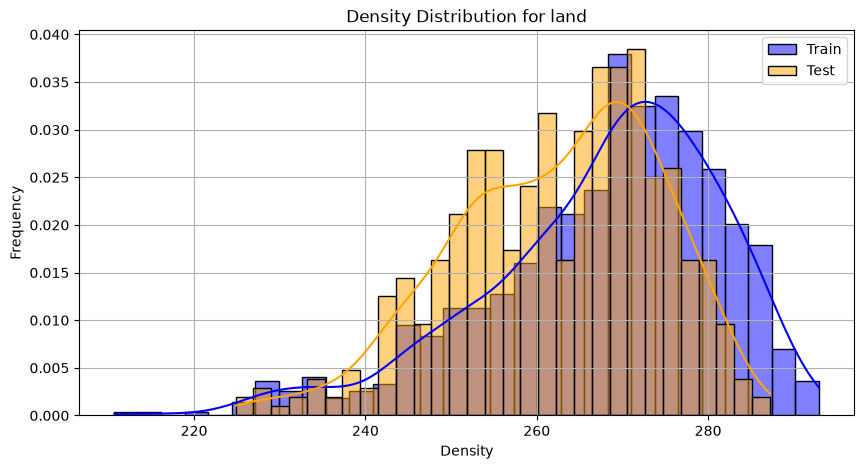

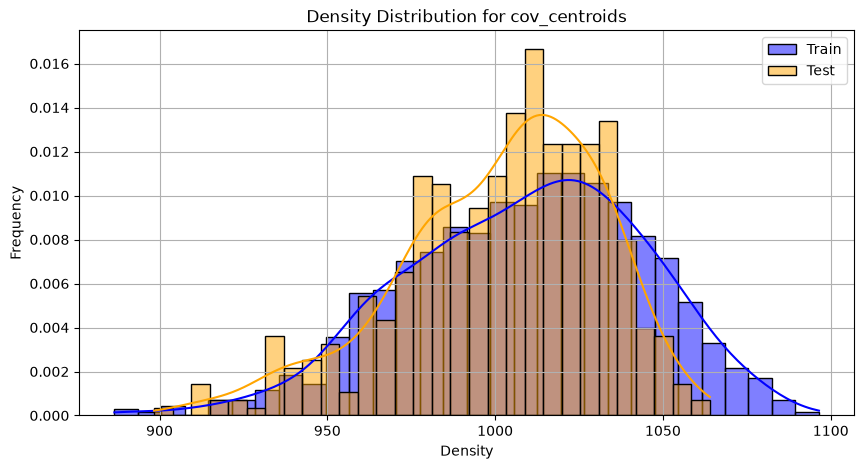

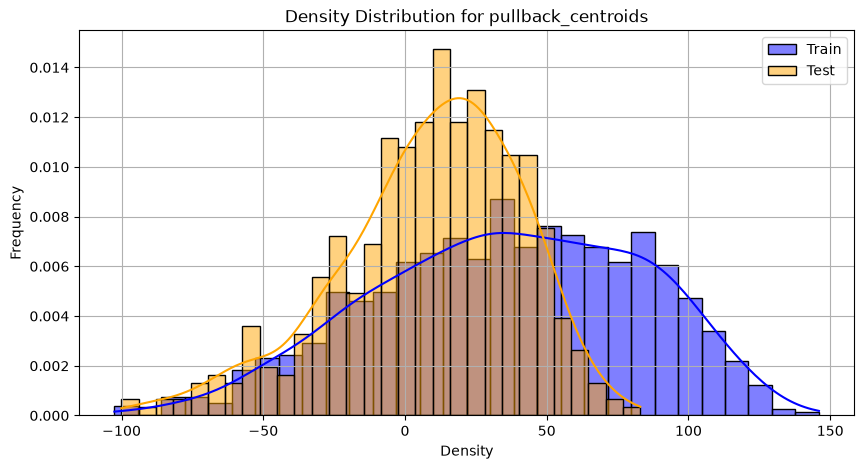

In [12]:
for cometric_type, densities_res in all_densities.items():
    p_train = densities_res["train"]
    p_test = densities_res["test"]
    plt.figure(figsize=(10, 5))
    sns.histplot(
        p_train.numpy(),
        color='blue',
        label='Train',
        kde=True,
        stat="density",
        bins=30,
        alpha=0.5,
    )
    sns.histplot(
        p_test.numpy(),
        color='orange',
        label='Test',
        kde=True,
        stat="density",
        bins=30,
        alpha=0.5,
    )
    plt.title(f"Density Distribution for {cometric_type}")
    plt.xlabel("Density")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid()
    plt.show()